# Local Deflection Chain Fitting for Through-Going Muons

Implements the Differentiable Local Deflection Chain from `deflections.md`. The track is
parameterized **autoregressively** as a sequence of connected straight segments where the
optimization parameters are the local scattering angles at each joint.

This formulation is:
- **Fully differentiable** (uses `jax.lax.scan` + vectorized segment construction)
- **Physically constrained** (Highland MCS prior on polar scattering angles)
- **JIT-compatible** (no Python loops inside the forward pass)

## Fitting Stages

1. **Stage 1**: Fix dE/dx to mean (1.887 MeV/cm), fit only chain deflection angles with MCS Highland prior → physical track shape
2. **Stage 2**: Warm-start from Stage 1; jointly fit deflection angles + per-segment dE/dx (split Student-t prior regularized)
3. **Stage 3**: Warm-start from Stage 2; jointly fit deflection angles + per-segment dE/dx + $A_b$ (Birks recombination)

## Key Design Decisions

- `deflection_chain_forward` uses `jax.lax.scan` (O(N) trace-time, not O(N) loop unrolling)
- `chain_to_fine_segments` is fully vectorized (no Python `for` loops over fields)
- `simulate_wfs_static` correctly uses `simulate_signals_new` (not the legacy `simulate_signals`)
- Each stage warm-starts from the previous stage's optimized parameters
- A Highland formula MCS prior regularizes unphysical kinks in all stages

In [1]:
import sys, os, dataclasses, pickle
PROJECT = '/sdf/group/neutrino/pgranger/larnd-sim-jax'
sys.path.insert(0, PROJECT)
sys.path.insert(0, f'{PROJECT}/src')
os.chdir(PROJECT)

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from functools import partial
from scipy.optimize import minimize
import time

from optimize.dataio import TracksDataset, TgtTracksDataset, np_from_structured
from larndsim.consts_jax import build_params_class, load_detector_properties, load_lut
from larndsim.sim_jax import (
    simulate_wfs, simulate_probabilistic, pad_to_closest_multiple, get_roi_counts,
    simulate_drift_new, simulate_signals_new
)
from optimize.dedx_utils import (
    split_student_t_nll,
    DEDX_SPLIT_NU_L, DEDX_SPLIT_NU_R,
    DEDX_SPLIT_SCALE_L, DEDX_SPLIT_SCALE_R,
    DEDX_SPLIT_LOC
)

print('JAX devices:', jax.devices())


JAX devices: [CpuDevice(id=0)]


## 1. Load Data

Load the through-going muon target and the linear-guess simulation. The target provides the true track shape; the simulation provides the initial straight-line guess.

In [ ]:
INPUT_SIM = '/sdf/group/neutrino/pgranger/lads-data/linear_guess_segments.h5'
INPUT_TGT = '/sdf/data/neutrino/cyifan/diffsim_input/true_through_muon_edep_10cm_vol1cm.h5'

# --- Configuration ---
MAX_BATCHES = 5        # number of batches to load (each typically has 3–5 tracks)
MIN_TRACK_LEN_CM = 5.0 # skip very short tracks

dataset_sim = TracksDataset(
    filename=INPUT_SIM, nevents=-1, max_nbatch=MAX_BATCHES, random_nevents=True,
    data_seed=1, track_len_sel=2.0, max_abs_costheta_sel=0.966,
    min_abs_segz_sel=15.0, track_z_bound=28.0, max_batch_len=200.0,
    chopped=True, pad=True, electron_sampling_resolution=0.01
)
dataset_target = TgtTracksDataset(
    filename=INPUT_TGT, dataset_sim=dataset_sim,
    chopped=True, pad=True, electron_sampling_resolution=0.01
)

fields = tuple(dataset_sim.get_track_fields())
tgt_fields = list(dataset_target.tgt_track_fields)
event_idx = fields.index('eventID')
track_idx = fields.index('trackID')
print(f'Loaded {len(dataset_sim)} batches  ({len(fields)} fields per segment)')

# --- Unchopped dataset for geometry (entry/exit endpoints) ---
ds_raw = TracksDataset(
    filename=INPUT_TGT, nevents=-1, max_nbatch=MAX_BATCHES, random_nevents=True,
    data_seed=1, track_len_sel=2.0, max_abs_costheta_sel=0.966,
    min_abs_segz_sel=15.0, track_z_bound=28.0, max_batch_len=200.0,
    chopped=False, pad=False, electron_sampling_resolution=0.01
)
fields_raw = list(ds_raw.get_track_fields())
x_s_r, y_s_r, z_s_r = [fields_raw.index(k) for k in ('x_start', 'y_start', 'z_start')]
x_e_r, y_e_r, z_e_r = [fields_raw.index(k) for k in ('x_end', 'y_end', 'z_end')]
ev_idx_r  = fields_raw.index('eventID')
trk_idx_r = fields_raw.index('trackID')

# Build (eventID, trackID) → (entry_pt, exit_pt, raw_segs) lookup
raw_endpoint_map = {}
for bi in range(len(ds_raw)):
    rb = ds_raw[bi].reshape(-1, len(fields_raw))
    rb = rb[rb[:, ev_idx_r] >= 0]
    for ev_tr in np.unique(np.column_stack([rb[:, ev_idx_r], rb[:, trk_idx_r]]), axis=0):
        ev, tr = int(ev_tr[0]), int(ev_tr[1])
        mask = (rb[:, ev_idx_r] == ev) & (rb[:, trk_idx_r] == tr)
        segs = rb[mask]
        entry_pt = np.array([segs[0, x_s_r],  segs[0, y_s_r],  segs[0, z_s_r]])
        exit_pt  = np.array([segs[-1, x_e_r], segs[-1, y_e_r], segs[-1, z_e_r]])
        raw_endpoint_map[(ev, tr)] = (entry_pt, exit_pt, segs)

# --- Enumerate all tracks across all batches ---
all_track_specs = []
for batch_idx in range(len(dataset_sim)):
    batch = dataset_sim[batch_idx].reshape(-1, len(fields))
    parent_ids = dataset_sim.get_parent_segment_ids(batch_idx)
    real = batch[parent_ids >= 0]
    if len(real) == 0:
        continue
    for ev_tr in np.unique(np.column_stack([real[:, event_idx], real[:, track_idx]]), axis=0):
        ev, tr = int(ev_tr[0]), int(ev_tr[1])
        if (ev, tr) not in raw_endpoint_map:
            continue
        entry_pt, exit_pt, raw_segs = raw_endpoint_map[(ev, tr)]
        total_len = float(np.linalg.norm(exit_pt - entry_pt))
        if total_len < MIN_TRACK_LEN_CM:
            continue
        all_track_specs.append({
            'batch_idx': batch_idx, 'ev': ev, 'tr': tr,
            'entry_pt': entry_pt, 'exit_pt': exit_pt,
            'total_len': total_len, 'raw_segs': raw_segs,
        })

print(f'Found {len(all_track_specs)} tracks across {len(dataset_sim)} batches:')
for spec in all_track_specs:
    print(f'  batch={spec["batch_idx"]} ev={spec["ev"]} tr={spec["tr"]:2d}  '
          f'L={spec["total_len"]:5.1f} cm  '
          f'entry=({spec["entry_pt"][0]:.1f}, {spec["entry_pt"][1]:.1f}, {spec["entry_pt"][2]:.1f})')


INFO:optimize.dataio:-- The used simulation data includes a total track length of 161.14767265319824 cm.
INFO:optimize.dataio:-- The number of simulation batches is 1.
INFO:optimize.dataio:-- The used target data includes a total track length of 160.77203369140625 cm.
INFO:optimize.dataio:-- The number of target batches is 1.


Full sim batch shape: (16161, 30)
Full tgt batch shape: (16101, 30)
Parent segment IDs shape: (16161,)
Found 4 tracks in the batch
  Track 0: eventID=0, trackID=4, segments=4900
  Track 1: eventID=1, trackID=1, segments=6930
  Track 2: eventID=1, trackID=2, segments=2450
  Track 3: eventID=1, trackID=4, segments=1881

Selecting track: eventID=1, trackID=1
Selected sim track shape: (6930, 30)
Selected tgt track shape: (6930, 30)


INFO:optimize.dataio:-- The used simulation data includes a total track length of 112.27089881896973 cm.
INFO:optimize.dataio:-- The number of simulation batches is 1.


Raw (unchopped) target segments for this track: 0


IndexError: index 0 is out of bounds for axis 0 with size 0

## 2. Load Detector and Response LUT

In [3]:
Params = build_params_class(['Ab', 'kb'])
ref_params = load_detector_properties(
    Params, 'src/larndsim/detector_properties/module0.yaml',
    'src/larndsim/pixel_layouts/multi_tile_layout-2.4.16_v4.yaml'
)
response, ref_params = load_lut('src/larndsim/detector_properties/response_44.npy', ref_params)

ab_nominal = 0.8348813503927325
kb_nominal = 0.04860
params_true = ref_params.replace(Ab=jnp.array(ab_nominal), kb=jnp.array(kb_nominal))
print('Detector parameters loaded successfully')

INFO:larndsim.consts_jax:Loading response from numpy array


Detector parameters loaded successfully


## 3. Algorithm Definitions

- **3a** — Core JAX chain kinematic functions (`highland_sigma_mcs`, `deflection_chain_forward`, `chain_to_fine_segments`, `make_straight_chain_init`)
- **3b** — `TrackContext` dataclass + `build_per_track_context` + `extract_track_arrays`
- **3c** — `simulate_wfs_static` + `make_chain_loss_fn` (factory, no global state)
- **3d** — `make_stage_fns` + `run_stage1/2/3` (JIT-wrapped L-BFGS-B runners)
- **3e** — Visualization helpers (`plot_track_diagnostics`, residuals, pixel ADC map)

In [4]:
# ── 3a: Core JAX chain kinematic functions ────────────────────────────────

N_FINE_PER_SEG = 20     # fine sub-segments per chain segment
mean_dedx      = 1.887  # MeV/cm — MIP muon in LAr
_X0_LAR_CM     = 14.0   # radiation length of liquid argon [cm]


def highland_sigma_mcs(step_length_cm: float, momentum_GeV: float = 3.0) -> float:
    """Expected 1-sigma MCS polar angle per step [rad], Highland formula."""
    ds_x0 = step_length_cm / _X0_LAR_CM
    return float((0.0136 / momentum_GeV) * np.sqrt(ds_x0) * (1.0 + 0.038 * np.log(ds_x0)))


def _build_local_basis(u):
    """Differentiable transverse basis (v, w) orthogonal to u."""
    ref_y = jnp.array([0.0, 1.0, 0.0])
    ref_x = jnp.array([1.0, 0.0, 0.0])
    cy = jnp.linalg.cross(u, ref_y)
    cx = jnp.linalg.cross(u, ref_x)
    cross = jnp.where(jnp.linalg.norm(cy) > 1e-4, cy, cx)
    v = cross / jnp.linalg.norm(cross)
    return v, jnp.linalg.cross(u, v)


def deflection_chain_forward(x0, theta0, phi0, dtheta, dphi, step_length):
    """Autoregressive forward kinematics via jax.lax.scan.

    Returns
    -------
    positions  : (N+1, 3) — chain nodes including exit point
    directions : (N, 3)   — segment unit vectors
    """
    u0 = jnp.array([
        jnp.sin(theta0) * jnp.cos(phi0),
        jnp.sin(theta0) * jnp.sin(phi0),
        jnp.cos(theta0),
    ])
    u0 = u0 / jnp.linalg.norm(u0)

    def step(carry, angles):
        pos, u = carry
        dth, dph = angles[0], angles[1]
        v, w = _build_local_basis(u)
        ct, st = jnp.cos(dth), jnp.sin(dth)
        cp, sp = jnp.cos(dph), jnp.sin(dph)
        u_next = ct * u + st * cp * v + st * sp * w
        u_next = u_next / jnp.linalg.norm(u_next)
        pos_next = pos + step_length * u
        return (pos_next, u_next), (pos_next, u_next)

    angles = jnp.stack([dtheta, dphi], axis=1)   # (N-1, 2)
    (pos_last, u_last), (pos_mid, u_mid) = jax.lax.scan(step, (x0, u0), angles)

    positions  = jnp.concatenate([x0[None], pos_mid,
                                   (pos_last + step_length * u_last)[None]], axis=0)
    directions = jnp.concatenate([u0[None], u_mid], axis=0)
    return positions, directions


def chain_to_fine_segments(pos, direc, dE_per_seg, fields, n_fine_per_seg=N_FINE_PER_SEG):
    """Convert N chain nodes → N*n_fine_per_seg fine simulation segments (vectorised)."""
    n_seg   = pos.shape[0] - 1
    dE_ps   = dE_per_seg[:n_seg]
    n_f_tot = n_seg * n_fine_per_seg

    p_s = pos[:-1];  p_e = pos[1:]          # (n_seg, 3)
    t_s = jnp.linspace(0.0, 1.0, n_fine_per_seg + 1)[:-1]
    t_e = t_s + 1.0 / n_fine_per_seg

    dp   = (p_e - p_s)[:, None, :]
    p_fs = (p_s[:, None, :] + t_s[None, :, None] * dp).reshape(n_f_tot, 3)
    p_fe = (p_s[:, None, :] + t_e[None, :, None] * dp).reshape(n_f_tot, 3)
    p_fm = 0.5 * (p_fs + p_fe)

    seg_vecs = p_fe - p_fs
    seg_lens = jnp.sqrt(jnp.sum(seg_vecs ** 2, axis=-1) + 1e-10)
    dE_fine  = jnp.repeat(dE_ps / n_fine_per_seg, n_fine_per_seg)
    dedx_f   = dE_fine / jnp.maximum(seg_lens, 1e-10)

    out = jnp.zeros((n_f_tot, len(fields)), dtype=jnp.float32)
    field_map = {
        'x_start': p_fs[:, 0], 'y_start': p_fs[:, 1], 'z_start': p_fs[:, 2],
        'x_end':   p_fe[:, 0], 'y_end':   p_fe[:, 1], 'z_end':   p_fe[:, 2],
        'x':       p_fm[:, 0], 'y':       p_fm[:, 1], 'z':       p_fm[:, 2],
        'dx':      seg_lens,   'dE':       dE_fine,    'dEdx':    dedx_f,
        'eventID': jnp.zeros(n_f_tot), 'trackID': jnp.zeros(n_f_tot),
        'pdg_id':  jnp.full(n_f_tot, 13.0), 'pixel_plane': jnp.zeros(n_f_tot),
        't0':      jnp.zeros(n_f_tot),
    }
    for name, vals in field_map.items():
        if name in fields:
            out = out.at[:, fields.index(name)].set(vals)
    return out


def make_straight_chain_init(entry_pt, exit_pt, n_segments):
    """Straight-line initialisation: returns (theta0, phi0, dtheta, dphi, step_len, total_len)."""
    d = exit_pt - entry_pt
    L = float(np.linalg.norm(d))
    u = d / L
    return (float(np.arccos(np.clip(u[2], -1.0, 1.0))),
            float(np.arctan2(u[1], u[0])),
            np.zeros(n_segments - 1, dtype=np.float32),
            np.zeros(n_segments - 1, dtype=np.float32),
            L / n_segments, L)


print('Chain kinematic functions defined.')


Generating target simulation...


/usr/local/lib/python3.10/dist-packages/jax/_src/numpy/array_methods.py:122: UserWarning: Explicitly requested dtype <class 'jax.numpy.int64'> requested in astype is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return lax_numpy.astype(self, dtype, copy=copy, device=device)
/sdf/group/neutrino/pgranger/larnd-sim-jax/src/larndsim/detsim_jax.py:274: UserWarning: Explicitly requested dtype <class 'jax.numpy.int64'> requested in array is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return jnp.where(outside, jnp.array(-1, dtype=jnp.int64), pid)
INFO:larndsim.sim_jax:Padding from shape (95,) to target shape (128,) with pad va

Target pixels: 92
Padded small nb: 128, large nb: 128


## 3b — Per-Track Context and Helper Functions

`TrackContext` dataclass + `build_per_track_context` factory (computes per-track pixel list,
σ_MCS, psn/pln) + `extract_track_arrays`, `pack_chain`, `unpack_chain`.

These depend on the chain kinematic functions defined above.

In [5]:
# ── 3b: Per-track context dataclass + factory ─────────────────────────────

@dataclasses.dataclass
class TrackContext:
    """All per-track constants needed by the loss function and stage runners."""
    x0_fixed:       jnp.ndarray   # (3,)  fixed entry point
    step_len:       float
    total_len:      float
    sigma_mcs:      float          # Highland 1-σ for this step length [rad]
    n_chain:        int
    theta0_i:       float
    phi0_i:         float          # normalised to [0, 2π]
    dtheta_i:       np.ndarray
    dphi_i:         np.ndarray
    x0_chain:       np.ndarray     # packed initial parameter vector
    bounds_chain:   list
    n_chain_params: int            # = 2 + 2*(n_chain-1)
    target_pixels:  jnp.ndarray
    target_adc:     jnp.ndarray    # (n_target_pix, n_ticks)
    fixed_pixels:   jnp.ndarray    # combined + padded pixel list
    psn:            int            # padded small-ROI count (multiple of 128)
    pln:            int            # padded large-ROI count


def build_per_track_context(entry_pt, exit_pt, tracks_tgt_fine, tracks_sim_fine,
                             params_true, response, fields,
                             target_step_len=1.5):
    """Build a TrackContext for one track.

    Parameters
    ----------
    entry_pt, exit_pt : (3,) arrays — track endpoints
    tracks_tgt_fine   : (N, F) array of fine target segments
    tracks_sim_fine   : (N, F) array of fine sim (initial-guess) segments
    params_true       : detector params container
    response          : LUT response array
    fields            : tuple of field names (module-level global is fine)
    target_step_len   : desired chain segment length [cm]
    """
    total_len = float(np.linalg.norm(exit_pt - entry_pt))
    n_chain   = max(4, min(30, round(total_len / target_step_len)))

    # --- straight-line initialisation ---
    theta0_i, phi0_i, dtheta_i, dphi_i, step_len, total_len = \
        make_straight_chain_init(entry_pt, exit_pt, n_chain)
    phi0_i    = float(phi0_i % (2 * np.pi))   # keep inside [0, 2π] bounds
    sigma_mcs = highland_sigma_mcs(step_len, momentum_GeV=3.0)
    x0_fixed  = jnp.array(entry_pt, dtype=jnp.float32)

    # --- initial chain → fine segments (for pixel union) ---
    dE_init      = np.full(n_chain, mean_dedx * step_len, dtype=np.float32)
    pos_i, dir_i = deflection_chain_forward(
        x0_fixed, theta0_i, phi0_i,
        jnp.array(dtheta_i), jnp.array(dphi_i), step_len)
    track_fine_i = chain_to_fine_segments(
        pos_i, dir_i, jnp.array(dE_init), fields, N_FINE_PER_SEG)

    # --- target simulation → target ADC ---
    # simulate_wfs returns (wfs, unique_pixels)
    tgt_jax     = jnp.array(tracks_tgt_fine, dtype=jnp.float32)
    wfs_t, up_t = simulate_wfs(params_true, response, tgt_jax, fields)
    up_t_p      = pad_to_closest_multiple(up_t,  multiple=128, pad_value=-1, pad_front=True)
    wfs_t_p     = pad_to_closest_multiple(wfs_t, dims_to_pad=(0,), multiple=128,
                                          pad_value=0.0, pad_front=True)
    nb_s, nb_l = get_roi_counts(params_true, wfs_t_p)
    psn = int(((int(nb_s) + 127) // 128) * 128)
    pln = int(((int(nb_l) + 127) // 128) * 128)
    adcs_d, _, _, ticks_p, _ = simulate_probabilistic(params_true, wfs_t_p, up_t_p, psn, pln)
    tgt_exp_adc   = jnp.sum(jnp.exp(ticks_p) * adcs_d, axis=1)
    valid_tgt     = (up_t_p >= 0) & (jnp.sum(tgt_exp_adc, axis=-1) > 0.05)
    target_pixels = up_t_p[valid_tgt]
    target_adc    = tgt_exp_adc[valid_tgt]

    # --- fixed pixel list (union of target pixels + initial-guess pixels) ---
    # simulate_wfs returns (wfs, unique_pixels); only the pixel IDs needed
    _, guess_pix = simulate_wfs(params_true, response, track_fine_i, fields)
    combined  = np.unique(np.concatenate([
        np.array(target_pixels),
        np.array(guess_pix[guess_pix >= 0])
    ]))
    combined  = np.append(combined, -1)   # ensure at least one -1 sentinel
    fixed_np  = np.array(pad_to_closest_multiple(
        jnp.array(combined), multiple=128, pad_value=-1, pad_front=False))
    fixed_np  = np.sort(fixed_np)         # sorted so searchsorted works correctly
    fixed_pixels = jnp.array(fixed_np)

    # --- L-BFGS-B parameter packaging ---
    n_chain_params = 2 + 2 * (n_chain - 1)
    x0_chain       = np.concatenate([[theta0_i, phi0_i], dtheta_i, dphi_i]).astype(np.float64)
    bounds_chain   = [(0.01, np.pi - 0.01), (0.0, 2 * np.pi)]
    bounds_chain  += [(0.0, np.pi / 4)] * (n_chain - 1)   # dtheta ∈ [0, π/4]
    bounds_chain  += [(-np.pi, np.pi)]  * (n_chain - 1)   # dphi ∈ (−π, π) symmetric

    return TrackContext(
        x0_fixed=x0_fixed, step_len=step_len, total_len=total_len,
        sigma_mcs=sigma_mcs, n_chain=n_chain,
        theta0_i=theta0_i, phi0_i=phi0_i, dtheta_i=dtheta_i, dphi_i=dphi_i,
        x0_chain=x0_chain, bounds_chain=bounds_chain, n_chain_params=n_chain_params,
        target_pixels=target_pixels, target_adc=target_adc,
        fixed_pixels=fixed_pixels, psn=psn, pln=pln,
    )


def extract_track_arrays(spec, dataset_sim, dataset_target):
    """Extract fine-grained sim and tgt segment arrays for one track spec."""
    bi, ev, tr = spec['batch_idx'], spec['ev'], spec['tr']
    tgt_ev_idx  = tgt_fields.index('eventID')
    tgt_trk_idx = tgt_fields.index('trackID')

    batch_sim  = dataset_sim[bi].reshape(-1, len(fields))
    parent_ids = dataset_sim.get_parent_segment_ids(bi)
    real_sim   = batch_sim[parent_ids >= 0]
    mask_sim   = (real_sim[:, event_idx] == ev) & (real_sim[:, track_idx] == tr)

    batch_tgt = dataset_target[bi].reshape(-1, len(tgt_fields))
    real_tgt  = batch_tgt[batch_tgt[:, tgt_ev_idx] >= 0]
    mask_tgt  = (real_tgt[:, tgt_ev_idx] == ev) & (real_tgt[:, tgt_trk_idx] == tr)

    return real_sim[mask_sim], real_tgt[mask_tgt]


def pack_chain(theta0, phi0, dtheta, dphi):
    return np.concatenate([[theta0, phi0], dtheta, dphi]).astype(np.float64)


def unpack_chain(x, n_chain):
    return x[0], x[1], x[2:2 + n_chain - 1], x[2 + n_chain - 1:2 + 2*(n_chain - 1)]


print('TrackContext, build_per_track_context, extract_track_arrays defined.')


Chain functions defined (using jax.lax.scan + vectorized segments)


## 3c — Simulation Helper and Loss Function Factory

`simulate_wfs_static`: runs the full simulation pipeline against a *fixed* (pre-built) pixel list so
XLA graph shapes are stable across optimization iterations.

`make_chain_loss_fn(ctx)`: factory that returns a loss function **closed over** the per-track
`TrackContext`. No global variables — each track gets its own compiled specialization.

In [6]:
# ── 3c: Static-pixel simulation + per-track loss factory ──────────────────

def simulate_wfs_static(params, tracks, fixed_px, fields):
    """Run drift + signal simulation against a fixed pre-built pixel list."""
    (_, pixels, nelectrons, t0_after_diff, long_diff,
     currents_idx, pIDs_neigh, currents_idx_neigh,
     nelectrons_neigh, t0_neigh) = simulate_drift_new(params, tracks, fields)

    pix_renum = jnp.searchsorted(fixed_px, pIDs_neigh.ravel(), method='sort')
    mask = (pix_renum < fixed_px.size) & (fixed_px[pix_renum] == pIDs_neigh.ravel())
    pix_renum = jnp.where(mask, pix_renum, 0)

    wfs = simulate_signals_new(
        params, fixed_px, pixels, t0_after_diff, response,
        nelectrons, long_diff, currents_idx,
        nelectrons_neigh, pix_renum, t0_neigh, currents_idx_neigh,
    )
    return wfs[:, 1:]   # drop garbage-collector tick 0


def make_chain_loss_fn(ctx: TrackContext):
    """Factory: return a chain MSE loss closed over a single TrackContext.

    All per-track constants (pixel list, psn/pln, geometry) are captured
    here so the returned function takes only differentiable JAX arguments.
    The Python `if` branches on dedx_log / ab_scale / mcs_sigma are resolved
    at trace-time, which lets jax.jit produce correct specializations.
    """
    x0_     = ctx.x0_fixed
    sl_     = ctx.step_len
    nc_     = ctx.n_chain
    fp_     = ctx.fixed_pixels
    psn_    = ctx.psn
    pln_    = ctx.pln
    tpx_    = ctx.target_pixels
    tadc_   = ctx.target_adc

    def chain_loss(theta0, phi0, dtheta, dphi,
                   dedx_log=None, ab_scale=None, mcs_sigma=None):
        pos, direc = deflection_chain_forward(x0_, theta0, phi0, dtheta, dphi, sl_)

        if dedx_log is not None:
            dedx_vals = jnp.maximum(jnp.exp(dedx_log), 1e-3)
        else:
            dedx_vals = jnp.full(nc_, mean_dedx, dtype=jnp.float32)
        dE = dedx_vals * sl_

        tracks_sim = chain_to_fine_segments(pos, direc, dE, fields, N_FINE_PER_SEG)

        if ab_scale is not None:
            params_run = params_true.replace(
                Ab=jnp.array(ab_nominal * ab_scale, dtype=jnp.float32))
        else:
            params_run = params_true

        wfs   = simulate_wfs_static(params_run, tracks_sim, fp_, fields)
        wfs_p = pad_to_closest_multiple(wfs, dims_to_pad=(0,), multiple=128,
                                        pad_value=0.0, pad_front=True)
        adcs_d, _, _, ticks_p, _ = simulate_probabilistic(
            params_run, wfs_p, fp_, padded_small_nb=psn_, padded_large_nb=pln_)
        exp_adc = jnp.sum(jnp.exp(ticks_p) * adcs_d, axis=1)

        idx    = jnp.searchsorted(fp_, tpx_)
        isafe  = jnp.clip(idx, 0, fp_.shape[0] - 1)
        hit    = (jnp.take(fp_, isafe) == tpx_)[:, None]
        guess  = jnp.where(hit, jnp.take(exp_adc, isafe, axis=0), 0.0)
        mse    = jnp.mean((guess - tadc_) ** 2)

        if mcs_sigma is not None:
            # Mean (not sum) so the weight is independent of chain length
            mcs_loss = jnp.mean(dtheta ** 2) / (2.0 * mcs_sigma ** 2)
            return mse + mcs_loss
        return mse

    return chain_loss


print('simulate_wfs_static and make_chain_loss_fn defined.')


Chain: 14 segments, step_length=1.34 cm, total_len=18.8 cm
Initial direction: theta0=2.5206 rad, phi0=4.6679 rad


Initial guess fine segments shape: (280, 30)
dx range: 0.067103 - 0.067106


INFO:larndsim.sim_jax:Padding from shape (27,) to target shape (128,) with pad value -1
INFO:larndsim.sim_jax:Padding from shape (6663,) to target shape (6784,) with pad value -1


Fixed pixel list size: 6784


/sdf/group/neutrino/pgranger/larnd-sim-jax/src/larndsim/sim_jax.py:37: UserWarning: Explicitly requested dtype float64 requested in full is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  buffer = jnp.full(target_shape, pad_value, dtype=x.dtype)


## 3d — JIT Stage Functions and L-BFGS-B Runners

`make_stage_fns(ctx, clf)` returns three JIT-compiled `value_and_grad` callables — one per stage —
all closed over the per-track context.  Calling it once per track triggers XLA compilation; all
subsequent L-BFGS-B iterations reuse the compiled kernel.

`run_stage1/2/3` drive `scipy.optimize.minimize` and return `(OptimizeResult, history)` where
`history` is a list of `{loss, grad_norm}` dicts (plus a `t` entry on the last element).

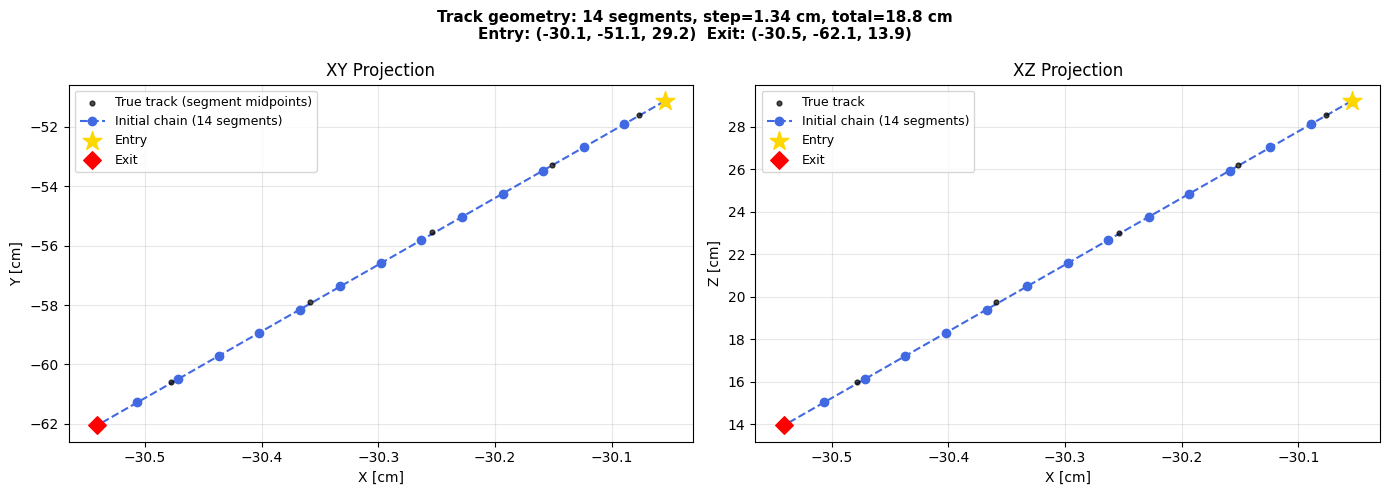

Highland MCS sigma: 1.28 mrad  (step=1.34 cm, p=3 GeV)


In [8]:
# ── 3d: make_stage_fns + run_stage1/2/3 ───────────────────────────────────

def make_stage_fns(ctx: TrackContext, clf):
    """Return three JIT-compiled (value, grad) functions for stages 1, 2, 3.

    clf = make_chain_loss_fn(ctx).  The three specializations have different
    static signatures (dedx_log / ab_scale present or absent) so JAX compiles
    them independently.
    """
    sigma = jnp.array(ctx.sigma_mcs, dtype=jnp.float32)

    def _s1(th, ph, dt, dp):
        return clf(th, ph, dt, dp, mcs_sigma=sigma)

    def _s2(th, ph, dt, dp, ld):
        mse = clf(th, ph, dt, dp, dedx_log=ld, mcs_sigma=sigma)
        prior = split_student_t_nll(
            jnp.maximum(jnp.exp(ld), 1e-3),
            DEDX_SPLIT_NU_L, DEDX_SPLIT_NU_R,
            DEDX_SPLIT_LOC, DEDX_SPLIT_SCALE_L, DEDX_SPLIT_SCALE_R)
        return mse + 0.1 * prior / ctx.n_chain

    def _s3(th, ph, dt, dp, ld, ab):
        mse = clf(th, ph, dt, dp, dedx_log=ld, ab_scale=ab, mcs_sigma=sigma)
        prior = split_student_t_nll(
            jnp.maximum(jnp.exp(ld), 1e-3),
            DEDX_SPLIT_NU_L, DEDX_SPLIT_NU_R,
            DEDX_SPLIT_LOC, DEDX_SPLIT_SCALE_L, DEDX_SPLIT_SCALE_R)
        return mse + 0.1 * prior / ctx.n_chain

    vg_s1 = jax.jit(jax.value_and_grad(_s1, argnums=(0, 1, 2, 3)))
    vg_s2 = jax.jit(jax.value_and_grad(_s2, argnums=(0, 1, 2, 3, 4)))
    vg_s3 = jax.jit(jax.value_and_grad(_s3, argnums=(0, 1, 2, 3, 4, 5)))
    return vg_s1, vg_s2, vg_s3


def _to_f32(v):
    return jnp.array(v, dtype=jnp.float32)

def _grad_concat(*arrays):
    return np.concatenate([np.atleast_1d(np.array(a, dtype=np.float64)) for a in arrays])


def run_stage1(ctx: TrackContext, vg, maxiter=200):
    history = []
    def fn(x):
        th, ph, dt, dp = unpack_chain(x, ctx.n_chain)
        l, g = vg(_to_f32(th), _to_f32(ph), _to_f32(dt), _to_f32(dp))
        grad = _grad_concat(g[0], g[1], g[2], g[3])
        history.append({'loss': float(l), 'grad_norm': float(np.linalg.norm(grad))})
        return float(l), grad
    t0 = time.time()
    res = minimize(fn, ctx.x0_chain.copy(), jac=True, method='L-BFGS-B',
                   bounds=ctx.bounds_chain, options={'maxiter': maxiter})
    elapsed = time.time() - t0
    if history: history[-1]['t'] = elapsed
    print(f'  Stage 1: {len(history):4d} iters  loss {res.fun:.4e}  time {elapsed:.1f}s')
    return res, history


def run_stage2(ctx: TrackContext, vg, res_s1, maxiter=200):
    history = []
    log_dedx_init = np.full(ctx.n_chain, float(np.log(DEDX_SPLIT_LOC)), dtype=np.float64)
    x0     = np.concatenate([res_s1.x, log_dedx_init])
    bounds = ctx.bounds_chain + [(np.log(0.5), np.log(5.0))] * ctx.n_chain
    def fn(x):
        th, ph, dt, dp = unpack_chain(x[:ctx.n_chain_params], ctx.n_chain)
        ld = x[ctx.n_chain_params:]
        l, g = vg(_to_f32(th), _to_f32(ph), _to_f32(dt), _to_f32(dp), _to_f32(ld))
        grad = _grad_concat(g[0], g[1], g[2], g[3], g[4])
        history.append({'loss': float(l), 'grad_norm': float(np.linalg.norm(grad))})
        return float(l), grad
    t0 = time.time()
    res = minimize(fn, x0, jac=True, method='L-BFGS-B',
                   bounds=bounds, options={'maxiter': maxiter})
    elapsed = time.time() - t0
    if history: history[-1]['t'] = elapsed
    print(f'  Stage 2: {len(history):4d} iters  loss {res.fun:.4e}  time {elapsed:.1f}s')
    return res, history


def run_stage3(ctx: TrackContext, vg, res_s2, maxiter=200):
    history = []
    x0     = np.concatenate([res_s2.x, [1.0]])
    bounds = ctx.bounds_chain + [(np.log(0.5), np.log(5.0))] * ctx.n_chain + [(0.5, 1.5)]
    def fn(x):
        th, ph, dt, dp = unpack_chain(x[:ctx.n_chain_params], ctx.n_chain)
        ld = x[ctx.n_chain_params:ctx.n_chain_params + ctx.n_chain]
        ab = x[ctx.n_chain_params + ctx.n_chain]
        l, g = vg(_to_f32(th), _to_f32(ph), _to_f32(dt), _to_f32(dp),
                  _to_f32(ld), _to_f32(ab))
        grad = _grad_concat(g[0], g[1], g[2], g[3], g[4], g[5])
        history.append({'loss': float(l), 'grad_norm': float(np.linalg.norm(grad))})
        return float(l), grad
    t0 = time.time()
    res = minimize(fn, x0, jac=True, method='L-BFGS-B',
                   bounds=bounds, options={'maxiter': maxiter})
    elapsed = time.time() - t0
    if history: history[-1]['t'] = elapsed
    print(f'  Stage 3: {len(history):4d} iters  loss {res.fun:.4e}  time {elapsed:.1f}s')
    return res, history


print('make_stage_fns, run_stage1, run_stage2, run_stage3 defined.')


In [9]:
# ── 3e: Visualization helpers ──────────────────────────────────────────────

_STAGE_COLORS = {'init': 'gray', 's1': 'royalblue', 's2': 'seagreen', 's3': 'tomato'}
_STAGE_LABELS = {'init': 'Initial', 's1': 'Stage 1 (pos)',
                 's2': 'Stage 2 (+dEdx)', 's3': 'Stage 3 (+Ab)'}


def _chain_nodes(ctx: TrackContext, th, ph, dt, dp):
    pos, _ = deflection_chain_forward(
        ctx.x0_fixed, th, ph,
        jnp.array(dt, dtype=jnp.float32),
        jnp.array(dp, dtype=jnp.float32),
        ctx.step_len)
    return np.array(pos)


def compute_all_chain_nodes(ctx: TrackContext, res_s1, res_s2, res_s3):
    """Reconstruct chain node arrays for initial guess and all three stages."""
    pos_i, _ = deflection_chain_forward(
        ctx.x0_fixed, ctx.theta0_i, ctx.phi0_i,
        jnp.array(ctx.dtheta_i), jnp.array(ctx.dphi_i), ctx.step_len)
    nodes = {'init': np.array(pos_i)}
    for key, res in [('s1', res_s1), ('s2', res_s2), ('s3', res_s3)]:
        th, ph, dt, dp = unpack_chain(res.x[:ctx.n_chain_params], ctx.n_chain)
        nodes[key] = _chain_nodes(ctx, th, ph, dt, dp)
    return nodes


def track_residuals(chain_nodes, tgt_xyz):
    """Min-distance from each true point to the fitted chain (point-to-segment)."""
    dists = []
    for p in tgt_xyz:
        best = np.inf
        for i in range(len(chain_nodes) - 1):
            a, b = chain_nodes[i], chain_nodes[i + 1]
            ab = b - a
            t = np.clip(np.dot(p - a, ab) / (np.dot(ab, ab) + 1e-12), 0.0, 1.0)
            best = min(best, np.linalg.norm(p - (a + t * ab)))
        dists.append(best)
    return np.array(dists)


def compute_pixel_adc_for_stage(ctx: TrackContext, res, fields, response,
                                 params_true, ab_nominal):
    """Re-run sim with fitted chain; return (exp_adc, fixed_pixels, px_x, px_y)."""
    th, ph, dt, dp = unpack_chain(res.x[:ctx.n_chain_params], ctx.n_chain)
    pos, direc = deflection_chain_forward(
        ctx.x0_fixed, th, ph,
        jnp.array(dt, dtype=jnp.float32), jnp.array(dp, dtype=jnp.float32),
        ctx.step_len)
    nc = ctx.n_chain
    if len(res.x) > ctx.n_chain_params:
        dE = jnp.array(np.exp(res.x[ctx.n_chain_params:ctx.n_chain_params + nc]) * ctx.step_len,
                        dtype=jnp.float32)
    else:
        dE = jnp.full(nc, mean_dedx * ctx.step_len, dtype=jnp.float32)
    ab_s = res.x[ctx.n_chain_params + nc] if len(res.x) > ctx.n_chain_params + nc else 1.0
    tracks_s = chain_to_fine_segments(pos, direc, dE, fields, N_FINE_PER_SEG)
    params_r  = params_true.replace(Ab=jnp.array(ab_nominal * ab_s, dtype=jnp.float32))
    wfs   = simulate_wfs_static(params_r, tracks_s, ctx.fixed_pixels, fields)
    wfs_p = pad_to_closest_multiple(wfs, dims_to_pad=(0,), multiple=128,
                                    pad_value=0.0, pad_front=True)
    adcs_d, px_x, px_y, ticks_p, _ = simulate_probabilistic(
        params_r, wfs_p, ctx.fixed_pixels, ctx.psn, ctx.pln)
    exp_adc = jnp.sum(jnp.exp(ticks_p) * adcs_d, axis=1)
    return (np.array(exp_adc), np.array(ctx.fixed_pixels),
            np.array(px_x), np.array(px_y))


def plot_track_diagnostics(key, result, raw_endpoint_map):
    """4-row × 3-col diagnostic figure for one fitted track."""
    ctx = result['ctx']
    hist_s1, hist_s2, hist_s3 = result['hist_s1'], result['hist_s2'], result['hist_s3']
    res_s1,  res_s2,  res_s3  = result['res_s1'],  result['res_s2'],  result['res_s3']
    cn = result['chain_nodes']

    batch_idx, ev, tr = key
    _, _, raw_segs = raw_endpoint_map[(ev, tr)]
    tgt_xs = raw_segs[:, fields_raw.index('x')]
    tgt_ys = raw_segs[:, fields_raw.index('y')]
    tgt_zs = raw_segs[:, fields_raw.index('z')]
    tgt_xyz = np.stack([tgt_xs, tgt_ys, tgt_zs], axis=1)

    fig, axes = plt.subplots(4, 3, figsize=(21, 24))
    fig.suptitle(
        f'Track Fit — batch={batch_idx} ev={ev} tr={tr}  '
        f'L={ctx.total_len:.1f} cm  N_chain={ctx.n_chain}',
        fontsize=13, fontweight='bold')

    # ── Row 1: geometry ──────────────────────────────────────────────────────
    for ci, (da, db, xl, yl, title) in enumerate([
        (0, 1, 'X [cm]', 'Y [cm]', 'XY Projection'),
        (0, 2, 'X [cm]', 'Z [cm]', 'XZ Projection'),
    ]):
        ax = axes[0, ci]
        ax.scatter(tgt_xyz[:, da], tgt_xyz[:, db], c='black', s=15, alpha=0.7,
                   label='True', zorder=5)
        for sn, nodes in cn.items():
            ax.plot(nodes[:, da], nodes[:, db],
                    color=_STAGE_COLORS[sn],
                    ls='--' if sn == 'init' else '-',
                    lw=1.0 if sn == 'init' else 1.8,
                    label=_STAGE_LABELS[sn])
        ax.scatter([float(ctx.x0_fixed[da])], [float(ctx.x0_fixed[db])],
                   marker='*', s=200, c='gold', zorder=6, label='Entry')
        ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(title)
        ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

    # Row 1 col 3: loss bar
    ax = axes[0, 2]
    init_loss = hist_s1[0]['loss'] if hist_s1 else float('nan')
    vals  = [init_loss, res_s1.fun, res_s2.fun, res_s3.fun]
    lbls  = ['Init', 'Stage 1', 'Stage 2', 'Stage 3']
    cols  = ['gray', 'royalblue', 'seagreen', 'tomato']
    bars  = ax.bar(lbls, vals, color=cols, alpha=0.8)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v * 1.05,
                f'{v:.3e}', ha='center', va='bottom', fontsize=8)
    ax.set_yscale('log'); ax.set_ylabel('Loss'); ax.set_title('Loss by Stage')
    ax.grid(True, alpha=0.3, axis='y')

    # ── Row 2: convergence ──────────────────────────────────────────────────
    for ci, (hist, lbl, col) in enumerate([
        (hist_s1, 'Stage 1 (pos+MCS)',    'royalblue'),
        (hist_s2, 'Stage 2 (pos+dEdx)',   'seagreen'),
        (hist_s3, 'Stage 3 (+Ab)',         'tomato'),
    ]):
        ax = axes[1, ci]
        if not hist:
            ax.text(0.5, 0.5, 'no data', transform=ax.transAxes, ha='center')
            continue
        iters  = range(len(hist))
        losses = [h['loss']      for h in hist]
        gnorms = [h['grad_norm'] for h in hist]
        ax.plot(iters, losses, color=col, lw=1.5, label='Loss')
        ax.set_yscale('log'); ax.set_xlabel('Iteration'); ax.set_ylabel('Loss')
        ax2 = ax.twinx()
        ax2.plot(iters, gnorms, color=col, lw=1.0, ls='--', alpha=0.55)
        ax2.set_yscale('log'); ax2.set_ylabel('‖∇‖', color='gray', fontsize=8)
        ax.set_title(f'{lbl}  ({len(hist)} iter, final={losses[-1]:.3e})')
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)

    # ── Row 3: physical parameters ──────────────────────────────────────────
    arc = np.arange(ctx.n_chain) * ctx.step_len + ctx.step_len / 2

    # dEdx profile
    ax = axes[2, 0]
    for sn, res, col in [('s2', res_s2, 'seagreen'), ('s3', res_s3, 'tomato')]:
        if len(res.x) > ctx.n_chain_params:
            ld = res.x[ctx.n_chain_params:ctx.n_chain_params + ctx.n_chain]
            ax.plot(arc, np.exp(ld), color=col, lw=1.8, marker='o', ms=4,
                    label=_STAGE_LABELS[sn])
    ax.axhline(mean_dedx, color='gray', ls='--', lw=1.5,
               label=f'MIP mean ({mean_dedx} MeV/cm)')
    ax.set_xlabel('Arc length [cm]'); ax.set_ylabel('dE/dx [MeV/cm]')
    ax.set_title('Fitted dE/dx Profile'); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

    # dtheta per joint
    ax = axes[2, 1]
    joints = np.arange(ctx.n_chain - 1)
    for sn, res, col in [('s1', res_s1, 'royalblue'), ('s2', res_s2, 'seagreen'),
                          ('s3', res_s3, 'tomato')]:
        _, _, dt, _ = unpack_chain(res.x[:ctx.n_chain_params], ctx.n_chain)
        ax.plot(joints, np.array(dt) * 1e3, color=col, lw=1.5,
                marker='o', ms=4, label=_STAGE_LABELS[sn])
    ax.axhspan(-ctx.sigma_mcs * 1e3, ctx.sigma_mcs * 1e3,
               alpha=0.12, color='gray', label=f'±σ_MCS ({ctx.sigma_mcs*1e3:.2f} mrad)')
    ax.set_xlabel('Joint index'); ax.set_ylabel('δθ [mrad]')
    ax.set_title('Angular Deflections per Joint'); ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

    # Pixel ADC scatter (target vs Stage 3 predicted)
    ax = axes[2, 2]
    try:
        pred_adc, pred_px, _, _ = compute_pixel_adc_for_stage(
            ctx, res_s3, fields, response, params_true, ab_nominal)
        tpx  = np.array(ctx.target_pixels)
        tadc = np.array(jnp.sum(ctx.target_adc, axis=-1))
        padc = np.array(jnp.sum(jnp.array(pred_adc), axis=-1))
        idx  = np.clip(np.searchsorted(np.array(ctx.fixed_pixels), tpx),
                       0, len(ctx.fixed_pixels) - 1)
        hit  = np.array(ctx.fixed_pixels)[idx] == tpx
        t_m, p_m = tadc[hit], padc[idx[hit]]
        sc = ax.scatter(t_m, p_m, c=np.arange(len(t_m)), cmap='viridis', s=30, alpha=0.8)
        plt.colorbar(sc, ax=ax, label='Pixel index')
        lim = max(t_m.max(), p_m.max()) * 1.05 if len(t_m) else 1.0
        ax.plot([0, lim], [0, lim], 'k--', lw=1, label='Perfect')
        ax.set_xlabel('Target ADC sum'); ax.set_ylabel('Predicted ADC sum (S3)')
        ax.set_title(f'Pixel ADC Match  ({len(t_m)} pixels)')
        ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    except Exception as exc:
        ax.text(0.5, 0.5, f'ADC map error:\n{exc}',
                transform=ax.transAxes, ha='center', va='center', fontsize=8)

    # ── Row 4: residuals + ADC diff + summary ───────────────────────────────
    resids = {sn: track_residuals(nodes, tgt_xyz) for sn, nodes in cn.items()}

    ax = axes[3, 0]
    for sn in ['init', 's1', 's2', 's3']:
        ax.hist(resids[sn], bins=np.linspace(0, 3, 60), alpha=0.5, density=True,
                color=_STAGE_COLORS[sn],
                label=f'{_STAGE_LABELS[sn]}  med={np.median(resids[sn]):.3f} cm')
    ax.set_xlabel('Distance to true track [cm]'); ax.set_ylabel('Density')
    ax.set_title('Track-to-True Residuals'); ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

    ax = axes[3, 1]
    try:
        if len(t_m) > 0:
            rel_diff = (p_m - t_m) / (t_m + 1e-8)
            ax.hist(rel_diff, bins=40, color='tomato', alpha=0.8, density=True)
            ax.axvline(0, color='black', ls='--', lw=1.5)
            ax.set_xlabel('(Pred − True) / True'); ax.set_ylabel('Density')
            ax.set_title(f'Pixel ADC Relative Residuals (S3)\n'
                         f'bias={rel_diff.mean():+.3f}  RMS={rel_diff.std():.3f}')
            ax.grid(True, alpha=0.3)
    except Exception:
        ax.text(0.5, 0.5, 'N/A', transform=ax.transAxes, ha='center', va='center')

    ax = axes[3, 2]
    ax.axis('off')
    nc = ctx.n_chain
    ab_fit = ab_nominal * (res_s3.x[ctx.n_chain_params + nc]
                           if len(res_s3.x) > ctx.n_chain_params + nc else 1.0)
    dex_m = float(np.exp(res_s2.x[ctx.n_chain_params:ctx.n_chain_params + nc]).mean()) \
        if len(res_s2.x) > ctx.n_chain_params else mean_dedx
    total_t = sum(h[-1].get('t', 0) for h in [hist_s1, hist_s2, hist_s3] if h)
    txt = (
        f'Track: b={batch_idx} ev={ev} tr={tr}\n'
        f'L={ctx.total_len:.1f} cm  N_chain={nc}\n'
        f'step={ctx.step_len:.2f} cm  σ_MCS={ctx.sigma_mcs*1e3:.2f} mrad\n'
        f'pixels (fixed/target): {len(ctx.fixed_pixels)}/{len(ctx.target_pixels)}\n\n'
        f'Loss:\n'
        f'  Init    {hist_s1[0]["loss"] if hist_s1 else float("nan"):.4e}\n'
        f'  Stage 1 {res_s1.fun:.4e}  ({len(hist_s1)} iter)\n'
        f'  Stage 2 {res_s2.fun:.4e}  ({len(hist_s2)} iter)\n'
        f'  Stage 3 {res_s3.fun:.4e}  ({len(hist_s3)} iter)\n\n'
        f'Fitted:\n'
        f'  dEdx mean (S2) {dex_m:.3f} MeV/cm\n'
        f'  Ab {ab_fit:.5f}  ({(ab_fit-ab_nominal)/ab_nominal*100:+.3f}%)\n\n'
        f'Resid median: {np.median(resids["init"]):.3f} → {np.median(resids["s3"]):.3f} cm\n'
        f'Total fit time: {total_t:.1f}s'
    )
    ax.text(0.05, 0.95, txt, transform=ax.transAxes, va='top', fontsize=9,
            family='monospace',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.85))

    plt.tight_layout(rect=[0, 0, 1, 0.97])
    return fig


print('Visualization helpers defined.')


Chain parameter vector: 28 elements
  theta0=2.5206, phi0=4.6679
  dtheta: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
  dphi:   [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 4. Per-Track Fitting Loop

Iterates over all tracks in `all_track_specs` (loaded above). For each track:

1. Extract per-track segment arrays from `dataset_sim` / `dataset_target`
2. Build `TrackContext` (per-track pixel list, psn/pln, geometry)
3. JIT-compile loss functions for all three stages
4. Run Stage 1 → Stage 2 → Stage 3 (each warm-starts from the previous)
5. Produce 4×3 diagnostic figure and save to `plots/`
6. Checkpoint results to `chain_fit_checkpoint.pkl` (resumable)

In [10]:
CHECKPOINT_FILE = 'chain_fit_checkpoint.pkl'
all_results = (pickle.load(open(CHECKPOINT_FILE, 'rb'))
               if os.path.exists(CHECKPOINT_FILE) else {})

os.makedirs('plots', exist_ok=True)
print(f'Starting multi-track chain fit: {len(all_track_specs)} tracks, '
      f'{len(all_results)} already in checkpoint.\n')

for spec_idx, spec in enumerate(all_track_specs):
    key = (spec['batch_idx'], spec['ev'], spec['tr'])

    if key in all_results:
        print(f'[{spec_idx+1}/{len(all_track_specs)}] Track {key} — already done, skipping.')
        continue

    print(f'\n{"="*65}')
    print(f'[{spec_idx+1}/{len(all_track_specs)}] '
          f'batch={spec["batch_idx"]}  ev={spec["ev"]}  tr={spec["tr"]}  '
          f'L={spec["total_len"]:.1f} cm')
    print('='*65)

    tracks_sim_trk, tracks_tgt_trk = extract_track_arrays(spec, dataset_sim, dataset_target)
    print(f'  Sim segs: {tracks_sim_trk.shape[0]}   Tgt segs: {tracks_tgt_trk.shape[0]}')

    print('  Building per-track context...')
    ctx = build_per_track_context(
        spec['entry_pt'], spec['exit_pt'],
        tracks_tgt_trk, tracks_sim_trk,
        params_true, response, fields)
    print(f'  N_chain={ctx.n_chain}  step={ctx.step_len:.2f} cm  '
          f'σ_MCS={ctx.sigma_mcs*1e3:.2f} mrad  '
          f'fixed_px={len(ctx.fixed_pixels)}  tgt_px={len(ctx.target_pixels)}  '
          f'psn={ctx.psn}  pln={ctx.pln}')

    print('  Building JIT loss functions...')
    clf = make_chain_loss_fn(ctx)
    vg_s1, vg_s2, vg_s3 = make_stage_fns(ctx, clf)

    # Trigger XLA compilation before timing Stage 1
    print('  Warming up JIT (XLA compilation)...')
    _ = vg_s1(_to_f32(ctx.theta0_i), _to_f32(ctx.phi0_i),
               _to_f32(ctx.dtheta_i), _to_f32(ctx.dphi_i))
    print('  JIT ready.')

    res_s1, hist_s1 = run_stage1(ctx, vg_s1)
    res_s2, hist_s2 = run_stage2(ctx, vg_s2, res_s1)
    res_s3, hist_s3 = run_stage3(ctx, vg_s3, res_s2)

    cn = compute_all_chain_nodes(ctx, res_s1, res_s2, res_s3)

    all_results[key] = dict(
        spec=spec, ctx=ctx,
        res_s1=res_s1, res_s2=res_s2, res_s3=res_s3,
        hist_s1=hist_s1, hist_s2=hist_s2, hist_s3=hist_s3,
        chain_nodes=cn,
    )

    fig = plot_track_diagnostics(key, all_results[key], raw_endpoint_map)
    fname = f"plots/chain_b{spec['batch_idx']}_ev{spec['ev']}_tr{spec['tr']}.png"
    fig.savefig(fname, dpi=120, bbox_inches='tight')
    plt.show()
    print(f'  Plot → {fname}')

    with open(CHECKPOINT_FILE, 'wb') as f:
        pickle.dump(all_results, f)
    print(f'  ✓ Checkpoint saved  ({len(all_results)}/{len(all_track_specs)} done)')

print(f'\n{"="*65}')
print(f'All {len(all_track_specs)} tracks done.')


STAGE 1: Position-only fit (dEdx fixed to mean, MCS prior)
Highland MCS sigma for step=1.34 cm, p=3 GeV: 1.28 mrad


INFO:larndsim.sim_jax:Padding from shape (6784, 2000) to target shape (6784, 2000) with pad value 0.0


Initial loss (with MCS prior): 5.658785e-01


INFO:larndsim.sim_jax:Padding from shape (6784, 2000) to target shape (6784, 2000) with pad value 0.0



Stage 1 results:
  Final loss: 5.658785e-01
  Iterations: 2
  Time: 4.0s
  theta0: 2.5206 (init: 2.5206)
  phi0:   4.6679 (init: 4.6679)
  dtheta RMS: 0.000 mrad


## 5. Cross-Track Summary

After all tracks are fitted, produce:
- **5a**: summary statistics table printed as a DataFrame + saved as `chain_fit_summary.csv`
- **5b**: 2×2 aggregated plot — geometry overlay, loss improvement bar, residual box plots

In [11]:
# ── 5a: Summary table ─────────────────────────────────────────────────────
if not all_results:
    print('No results yet — run the fitting loop first.')
else:
    rows = []
    for key, r in all_results.items():
        bi, ev, tr = key
        ctx   = r['ctx']
        nc    = ctx.n_chain
        h1, h2, h3 = r['hist_s1'], r['hist_s2'], r['hist_s3']
        rs1, rs2, rs3 = r['res_s1'], r['res_s2'], r['res_s3']
        cn    = r['chain_nodes']

        init_loss = h1[0]['loss'] if h1 else float('nan')
        ab_fit = ab_nominal * (rs3.x[ctx.n_chain_params + nc]
                               if len(rs3.x) > ctx.n_chain_params + nc else 1.0)
        dedx_m = float(np.exp(rs2.x[ctx.n_chain_params:ctx.n_chain_params + nc]).mean()) \
            if len(rs2.x) > ctx.n_chain_params else mean_dedx
        _, _, raw_segs = raw_endpoint_map[(ev, tr)]
        tgt_xyz = np.stack([raw_segs[:, fields_raw.index(c)]
                            for c in ('x', 'y', 'z')], axis=1)
        resid_i = np.median(track_residuals(cn['init'], tgt_xyz))
        resid_3 = np.median(track_residuals(cn['s3'],   tgt_xyz))
        tot_t   = sum(h[-1].get('t', 0) for h in [h1, h2, h3] if h)

        rows.append({
            'batch': bi, 'ev': ev, 'tr': tr,
            'L (cm)':        f'{ctx.total_len:.1f}',
            'N_chain':       nc,
            'Loss init':     f'{init_loss:.3e}',
            'Loss S1':       f'{rs1.fun:.3e}',
            'Loss S2':       f'{rs2.fun:.3e}',
            'Loss S3':       f'{rs3.fun:.3e}',
            'dEdx S2':       f'{dedx_m:.3f}',
            'Ab fit':        f'{ab_fit:.5f}',
            'Ab bias %':     f'{(ab_fit - ab_nominal)/ab_nominal*100:+.3f}',
            'Resid init':    f'{resid_i:.3f}',
            'Resid S3 (cm)': f'{resid_3:.3f}',
            'Time (s)':      f'{tot_t:.1f}',
        })

    df = pd.DataFrame(rows)
    print(df.to_string(index=False))
    df.to_csv('chain_fit_summary.csv', index=False)
    print('\nSaved: chain_fit_summary.csv')


STAGE 2: Joint position + dEdx fit (warm-started from Stage 1)


INFO:larndsim.sim_jax:Padding from shape (6784, 2000) to target shape (6784, 2000) with pad value 0.0


Initial loss (Stage 2, warm-started): 4.480996e-01


INFO:larndsim.sim_jax:Padding from shape (6784, 2000) to target shape (6784, 2000) with pad value 0.0



Stage 2 results:
  Final loss: 4.480996e-01
  Iterations: 2
  Time: 4.0s
  dEdx range: [1.8740, 1.8740] MeV/cm
  dEdx mean:  1.8740 MeV/cm  (truth mean: 1.8870)
  dtheta RMS: 0.000 mrad


### 5b — Aggregated cross-track plots

In [12]:
# ── 5b: Cross-track aggregated plots ──────────────────────────────────────
if not all_results:
    print('No results yet.')
else:
    cmap_tab = plt.cm.tab10
    tcolors  = {k: cmap_tab(i % 10) for i, k in enumerate(all_results)}

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle(f'Cross-Track Summary — {len(all_results)} tracks', fontsize=14, fontweight='bold')

    # XY overlay
    ax = axes[0, 0]
    for key, r in all_results.items():
        bi, ev, tr = key
        _, _, raw_s = raw_endpoint_map[(ev, tr)]
        col = tcolors[key]
        ax.plot(raw_s[:, fields_raw.index('x')], raw_s[:, fields_raw.index('y')],
                '-', color=col, lw=1.5, alpha=0.55, label=f'ev={ev} tr={tr} (true)')
        n = r['chain_nodes']['s3']
        ax.plot(n[:, 0], n[:, 1], '--', color=col, lw=1.5, label=f'(S3 fit)')
    ax.set_xlabel('X [cm]'); ax.set_ylabel('Y [cm]')
    ax.set_title('XY: True (solid) vs Stage 3 (dashed)')
    ax.legend(fontsize=7, ncol=2); ax.grid(True, alpha=0.3)

    # XZ overlay
    ax = axes[0, 1]
    for key, r in all_results.items():
        bi, ev, tr = key
        _, _, raw_s = raw_endpoint_map[(ev, tr)]
        col = tcolors[key]
        ax.plot(raw_s[:, fields_raw.index('x')], raw_s[:, fields_raw.index('z')],
                '-', color=col, lw=1.5, alpha=0.55)
        n = r['chain_nodes']['s3']
        ax.plot(n[:, 0], n[:, 2], '--', color=col, lw=1.5)
    ax.set_xlabel('X [cm]'); ax.set_ylabel('Z [cm]')
    ax.set_title('XZ: True (solid) vs Stage 3 (dashed)')
    ax.grid(True, alpha=0.3)

    # Loss improvement bar
    ax = axes[1, 0]
    tnames = [f'b{k[0]}\nev{k[1]}\ntr{k[2]}' for k in all_results]
    inits  = [r['hist_s1'][0]['loss'] if r['hist_s1'] else float('nan')
              for r in all_results.values()]
    finals = [r['res_s3'].fun for r in all_results.values()]
    improv = [(i - f) / i * 100 for i, f in zip(inits, finals)]
    bars = ax.bar(tnames, improv, color=[tcolors[k] for k in all_results], alpha=0.85)
    for bar, imp in zip(bars, improv):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                f'{imp:.1f}%', ha='center', va='bottom', fontsize=9)
    ax.set_ylabel('Loss reduction (%)'); ax.set_title('Loss Improvement Init → Stage 3')
    ax.grid(True, alpha=0.3, axis='y')

    # Residual box plots across all tracks
    ax = axes[1, 1]
    stages = ['init', 's1', 's2', 's3']
    all_res_data = {s: [] for s in stages}
    for key, r in all_results.items():
        bi, ev, tr = key
        _, _, raw_s = raw_endpoint_map[(ev, tr)]
        xyz = np.stack([raw_s[:, fields_raw.index(c)] for c in ('x', 'y', 'z')], axis=1)
        for s in stages:
            all_res_data[s].extend(track_residuals(r['chain_nodes'][s], xyz).tolist())
    bp = ax.boxplot([all_res_data[s] for s in stages],
                    labels=['Initial', 'Stage 1', 'Stage 2', 'Stage 3'],
                    patch_artist=True,
                    medianprops={'color': 'black', 'lw': 2})
    for patch, col in zip(bp['boxes'], ['gray', 'royalblue', 'seagreen', 'tomato']):
        patch.set_facecolor(col); patch.set_alpha(0.7)
    ax.set_ylabel('Distance to true track [cm]')
    ax.set_title('Track Residuals — All Tracks Combined')
    ax.grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.savefig('plots/chain_fit_cross_track_summary.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Saved: plots/chain_fit_cross_track_summary.png')


STAGE 3: Joint position + dEdx + Ab fit (warm-started from Stage 2)


INFO:larndsim.sim_jax:Padding from shape (6784, 2000) to target shape (6784, 2000) with pad value 0.0


Initial loss (Stage 3, warm-started): 4.480996e-01


INFO:larndsim.sim_jax:Padding from shape (6784, 2000) to target shape (6784, 2000) with pad value 0.0



Stage 3 results:
  Final loss: 4.480996e-01
  Iterations: 2
  Time: 4.0s
  Ab fitted: 0.834881  (true: 0.834881)
  Ab bias:   +0.0000%
  dEdx range: [1.8740, 1.8740] MeV/cm
  dEdx mean:  1.8740 MeV/cm
  dtheta RMS: 0.000 mrad


## (end of notebook)

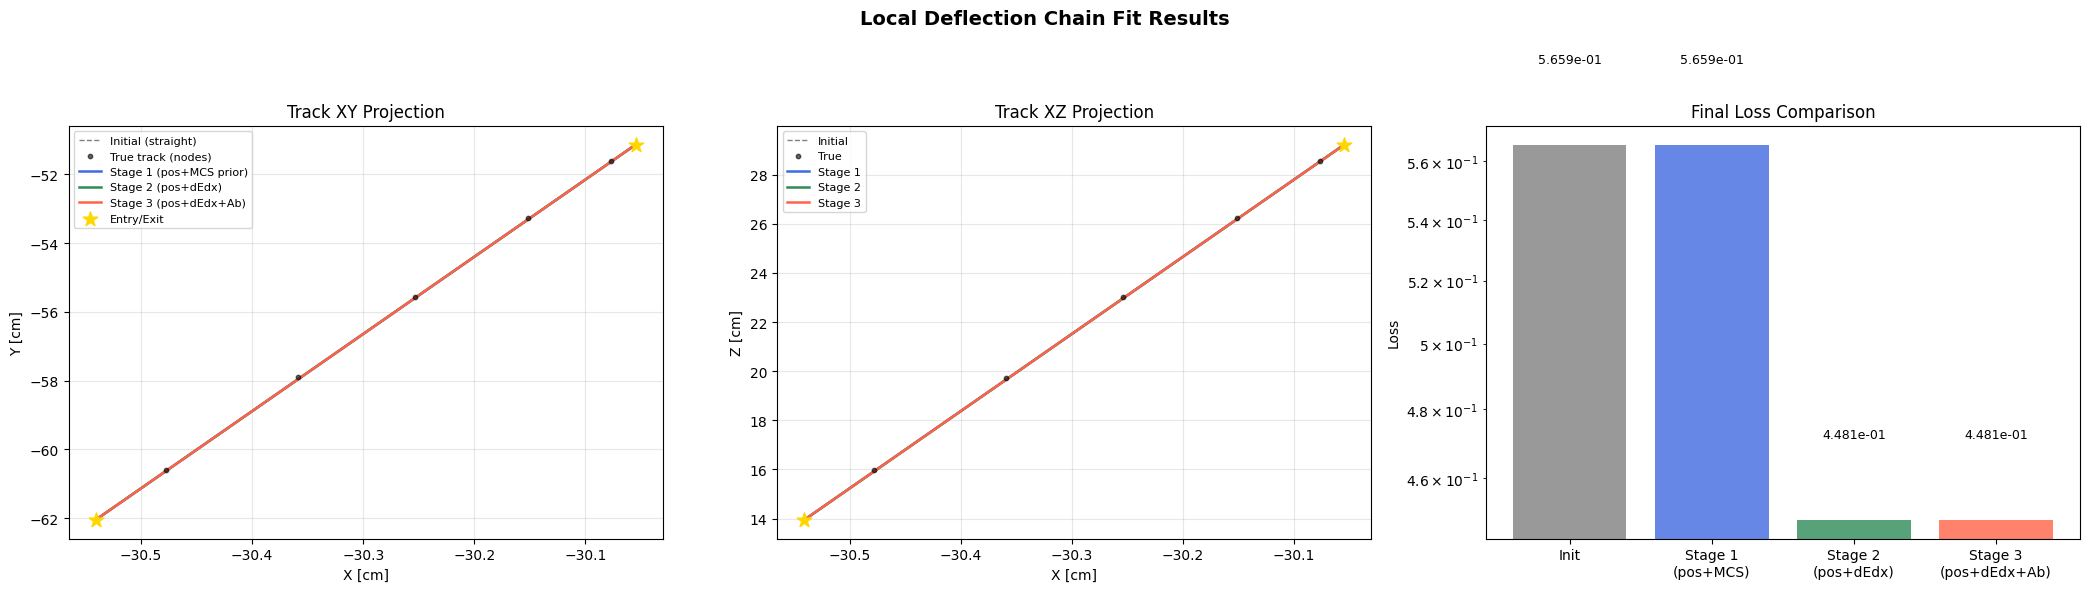


--- Summary Table ---
Stage                        Final Loss       Time (s)  
--------------------------------------------------------
Initial (straight line)      5.658785e-01     N/A       
Stage 1 (pos+MCS)            5.658785e-01     4.0       
Stage 2 (pos+dEdx)           4.480996e-01     4.0       
Stage 3 (pos+dEdx+Ab)        4.480996e-01     4.0       

Ab fitted: 0.834881  (true: 0.834881,  bias: +0.0000%)


In [13]:
# (cell cleared — replaced by fitting loop and cross-track summary above)


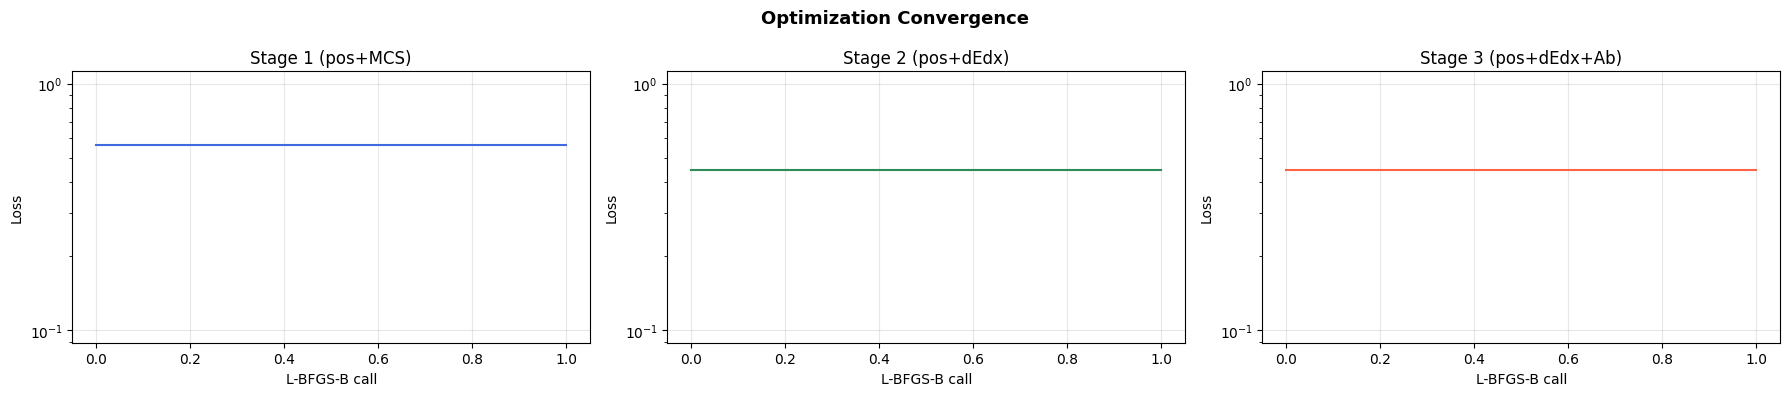

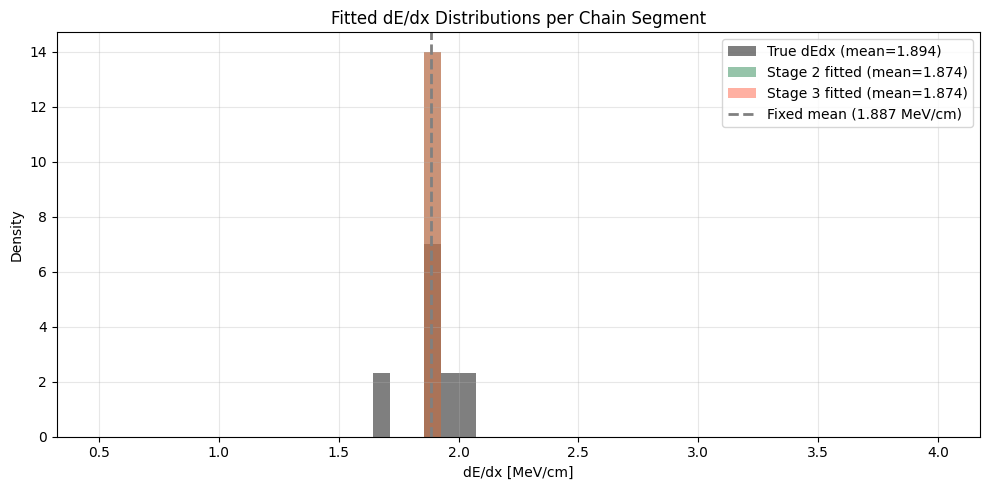

Angular deflection statistics (dtheta):
  Stage 1 (pos+MCS)             mean=0.000 mrad  max=0.000 mrad  RMS=0.000 mrad
  Stage 2 (pos+dEdx)            mean=0.000 mrad  max=0.000 mrad  RMS=0.000 mrad
  Stage 3 (pos+dEdx+Ab)         mean=0.000 mrad  max=0.000 mrad  RMS=0.000 mrad
  Highland sigma_MCS = 1.279 mrad


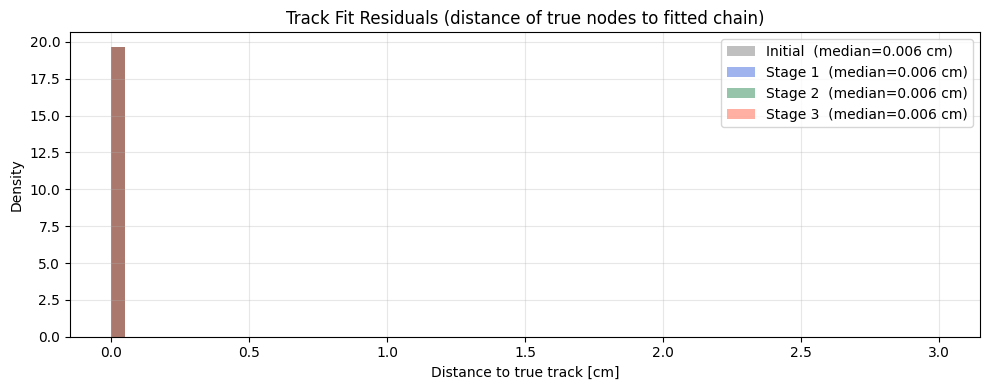


Notebook complete!


In [14]:
# (cell cleared — diagnostics now in plot_track_diagnostics and cross-track summary)
